### 이진 분류
: Banknote Authentication 데이터셋 : 진짜 지폐와 가짜 지폐를 판별<br>

- 데이터 : 1372개<br>
- 정답 : 0 -> 진짜, 1 -> 가짜<br>
- 입력특징 : 4개<br>
    variance(분산)	<br>
    skewness(왜도)  : 좌우 어느 방향으로 치우쳐져 있는지	<br>
    curtosis(첨도)  : 분포의 뾰족한 정도<br>
    entropy(엔트로피)   : 낮으면 특정값이나 패턴에 집중, 높으면 다양한 값이 나타나고 분포가 복잡함<br>

- 4개의 특징값(입력값)으로 사용하고, 결과(진짜지폐, 가짜지폐) 예측 

In [39]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np
import random

### Step 1. 데이터 불러오기 및 전처리

In [40]:
df = pd.read_csv('data_banknote_authentication.txt')
columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
df = pd.read_csv(
    'data_banknote_authentication.txt',
    names=columns
)

print(df.head())
print('데이터의 크기 :', df.shape)
print('클래스별 데이터 개수 :')
print(df['class'].value_counts().sort_index())

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
데이터의 크기 : (1372, 5)
클래스별 데이터 개수 :
class
0    762
1    610
Name: count, dtype: int64


In [41]:
# 입력데이트(x)와 정답데이터(y) 분리
X = torch.tensor(df[['variance', 'skewness', 'curtosis', 'entropy']].values,
                    dtype = torch.float32)      # (1372,4)
y = torch.tensor(df['class'].values, dtype = torch.float32).reshape(-1,1)       # (1372,1)형태의 2차원으로 만들어줌

# 클래스별로 학습/테스트 데이터를 나눔
torch.manual_seed(42)
train_indices = []
test_indices = []

# for class_value in [0,1]:
#     class_indices = []

#     for i in range(len(y)):
#         if y[i].item() == class_value:
#             class_indices.append(i)

# # 순서를 무작위로 섞기
# random.shuffle(class_indices)

# # 학습 80%, 테스트 20% 분리
# split = int(len(class_indices) *0.8)

# train_indices.extend(class_indices[:split])
# test_indices.extend(class_indices[split:])

for class_value in [0,1]:
    # where(0) : 조건을 만족하는 데이터 찾기. 결과는 튜플로 반환
    class_indices = torch.where(y.squeeze() == class_value)[0]

    # randperm() : 0부터 지정한 숫자까지의 정수를 무작위로 섞어서 반환
    class_indices = class_indices[torch.randperm(len(class_indices))]

    # 학습 80%, 테스트 20% 분리
    split = int(len(class_indices) *0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])

# 학습/테스트 데이터 섞기(클래스0 앞쪽에, 클래스1 뒤쪽에 몰려있는거 섞기)
train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

X_train = X[train_indices]      # X_train = (1097, 4)
X_test = X[test_indices]        # X_test = (275,4)
y_train = y[train_indices]      # y_train = (1097, 1)
y_test = y[test_indices]        # y_test = (275,1)

# 데이터 정규화. 데이터끼리 편차가 클 때 평균 0, 표준편차 1로 정규화 후 학습
mean = X_train.mean(dim=0)      # 행의 방향 즉, 열의 평균
std = X_train.std(dim=0). clamp(min=1e-8)

X_train = (X_train - mean)/std
X_test = (X_test -mean)/std

print('X_train :', X_train.shape)
print('y_train :', y_train.shape)
print('X_test :', X_test.shape)
print('y_test :', y_test.shape)

X_train : torch.Size([1097, 4])
y_train : torch.Size([1097, 1])
X_test : torch.Size([275, 4])
y_test : torch.Size([275, 1])


In [42]:
# DataLoader 생성
BATCH_SIZE = 32

train_DS = TensorDataset(X_train, y_train)
test_DS = TensorDataset(X_test, y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)
print(N)

1097


### Step 2. 모델 만들기


In [43]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()

### Step 3. 모델 학습 시키기

In [44]:
LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history=[]

model.train()
for ep in range(EPOCH):
    rloss = 0

    for x_batch, y_batch in train_DL:
        #inference
        y_hat = model(x_batch)

        # loss
        loss = criterion(y_hat, y_batch)

        # update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N
    loss_history.append(epoch_loss)

    print(f'Epoch : {ep+1}, train Loss : {epoch_loss:.4f}')
    print('-'*20)

Epoch : 1, train Loss : 0.5965
--------------------
Epoch : 2, train Loss : 0.4542
--------------------
Epoch : 3, train Loss : 0.3698
--------------------
Epoch : 4, train Loss : 0.3095
--------------------
Epoch : 5, train Loss : 0.2634
--------------------
Epoch : 6, train Loss : 0.2288
--------------------
Epoch : 7, train Loss : 0.2007
--------------------
Epoch : 8, train Loss : 0.1779
--------------------
Epoch : 9, train Loss : 0.1586
--------------------
Epoch : 10, train Loss : 0.1439
--------------------
Epoch : 11, train Loss : 0.1312
--------------------
Epoch : 12, train Loss : 0.1207
--------------------
Epoch : 13, train Loss : 0.1124
--------------------
Epoch : 14, train Loss : 0.1049
--------------------
Epoch : 15, train Loss : 0.0985
--------------------
Epoch : 16, train Loss : 0.0929
--------------------
Epoch : 17, train Loss : 0.0884
--------------------
Epoch : 18, train Loss : 0.0835
--------------------
Epoch : 19, train Loss : 0.0803
--------------------
Ep

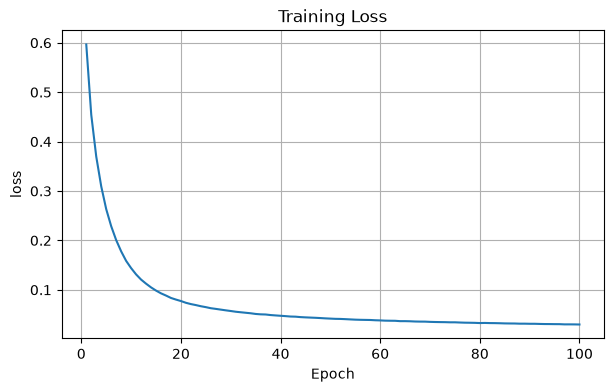

In [45]:
plt.figure(figsize=(7,4))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.title('Training Loss')
plt.grid()


### step 4. 모델 테스트하기

In [46]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for x_batch, y_batch in test_DL:
        y_hat = model(x_batch)
        pred = (y_hat >= 0.5).float()

        correct +=(pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct/total*100
print(f'Test accuracy : {correct}/{total} ({accuracy:.1f}%)')

Test accuracy : 269/275 (97.8%)
